In [1]:
import pandas as pd
from surprise import Dataset, Reader, KNNBaseline, CoClustering, SVD, SVDpp, NMF, NormalPredictor
from sklearn.model_selection import train_test_split
import time
from surprise import accuracy
from tabulate import tabulate
import matplotlib.pyplot as plt
import seaborn as sns
 


In [ ]:
ratings = pd.read_csv('ratings_clean.csv')
reader = Reader(rating_scale=(1,5))

X = ratings.copy()
Y = ratings['user_id']

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.3, random_state=1)

data = Dataset.load_from_df(X_train[['user_id', 'recipe_id', 'rating']], reader)

trainset = data.build_full_trainset()

testset = list(zip(X_test['user_id'], X_test['recipe_id'], X_test['rating']))



In [3]:
algorithms = [KNNBaseline(sim_options={"user_based": False}),
              SVD(random_state=1),
              SVDpp(random_state=1),
              NMF(random_state=1),
              CoClustering(random_state=1),
              NormalPredictor()]

In [4]:
#code from lab3 eval_metrics
from collections import defaultdict

def precision_recall_at_k(predictions, k=10, threshold=3.5):
    """Return precision and recall at k metrics for each user"""

    # First map the predictions to each user.
    user_est_true = defaultdict(list)
    for uid, _, true_r, est, _ in predictions:
        user_est_true[uid].append((est, true_r))

    precisions = dict()
    recalls = dict()
    for uid, user_ratings in user_est_true.items():

        # Sort user ratings by estimated value
        user_ratings.sort(key=lambda x: x[0], reverse=True)

        # Number of relevant items
        n_rel = sum((true_r >= threshold) for (_, true_r) in user_ratings)

        # Number of recommended items in top k
        n_rec_k = sum((est >= threshold) for (est, _) in user_ratings[:k])

        # Number of relevant and recommended items in top k
        n_rel_and_rec_k = sum(
            ((true_r >= threshold) and (est >= threshold))
            for (est, true_r) in user_ratings[:k]
        )

        # Precision@K: Proportion of recommended items that are relevant
        # When n_rec_k is 0, Precision is undefined. We here set it to 0.

        precisions[uid] = n_rel_and_rec_k / n_rec_k if n_rec_k != 0 else 0

        # Recall@K: Proportion of relevant items that are recommended
        # When n_rel is 0, Recall is undefined. We here set it to 0.

        recalls[uid] = n_rel_and_rec_k / n_rel if n_rel != 0 else 0
        
    precision = sum(prec for prec in precisions.values()) / len(precisions)
    recall = sum(rec for rec in recalls.values()) / len(recalls)

    return precision, recall

In [5]:
table = []
for algorithm in algorithms:
    start = time.time()
    algorithm.fit(trainset)
    fit_time = round(time.time() - start, 3)

    predictions = algorithm.test(testset)
    rmse = round(accuracy.rmse(predictions, verbose=False), 3)
    mae = round(accuracy.mae(predictions, verbose=False), 3)
    fcp = round(accuracy.fcp(predictions, verbose=False), 3)
    p,r = precision_recall_at_k(predictions, k=5, threshold=4)
    precision = round(p, 3)
    recall = round(r,3)

    table.append([str(algorithm).split(' ')[0].split('.')[-1],
                  rmse,
                  mae,
                  fcp,
                  precision,
                  recall,
                  fit_time])


Estimating biases using als...
Computing the msd similarity matrix...
Done computing similarity matrix.


In [6]:
item_avg_rating = X_train.groupby(['recipe_id'])['rating'].mean()

def cf_recipe_mean(user_id, recipe_id):
    if recipe_id in item_avg_rating:
        mean_rating = item_avg_rating[recipe_id]
    else:
        mean_rating = 3.0
    return mean_rating

predictions = []
for (user, recipe, true_r) in testset:
    est = cf_recipe_mean(user, recipe)
    predictions.append((user,recipe,true_r,est,None))

rmse = round(accuracy.rmse(predictions, verbose=False), 3)
mae = round(accuracy.mae(predictions, verbose=False), 3)
fcp = round(accuracy.fcp(predictions, verbose=False), 3)
p, r = precision_recall_at_k(predictions, k=5, threshold=4)
precision = round(p, 3)
recall = round(r, 3)

table.append(['Popularity', rmse, mae, fcp, precision, recall, 0])

In [7]:
header = [
    'Recommenders',
    'RMSE',
    'MAE',
    'FCP',
    'Precision',
    'Recall',
    'Train time'
]

print(tabulate(table, header, tablefmt='pipe'))

| Recommenders    |   RMSE |   MAE |   FCP |   Precision |   Recall |   Train time |
|:----------------|-------:|------:|------:|------------:|---------:|-------------:|
| KNNBaseline     |  0.702 | 0.412 | 0.582 |       0.909 |    0.873 |        4.549 |
| SVD             |  0.675 | 0.414 | 0.566 |       0.918 |    0.888 |        3.827 |
| SVDpp           |  0.674 | 0.409 | 0.569 |       0.92  |    0.89  |       26.325 |
| NMF             |  0.793 | 0.576 | 0.578 |       0.849 |    0.798 |       11.929 |
| CoClustering    |  0.707 | 0.408 | 0.598 |       0.899 |    0.864 |       12.242 |
| NormalPredictor |  0.878 | 0.581 | 0.474 |       0.816 |    0.76  |        0.216 |
| Popularity      |  0.697 | 0.441 | 0.578 |       0.914 |    0.884 |        0     |


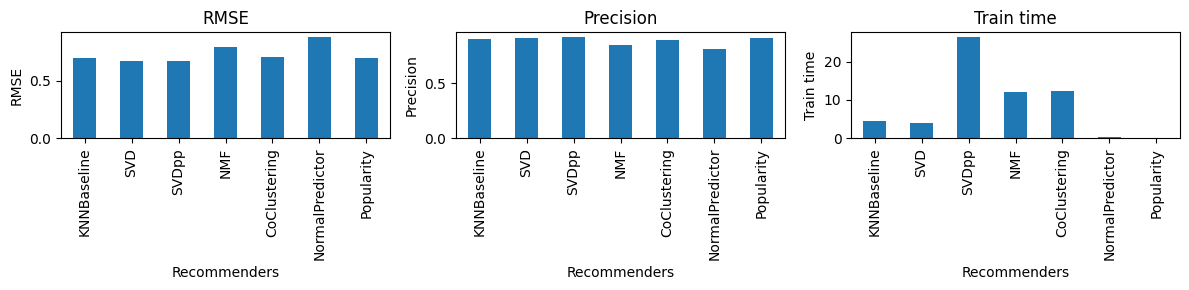

In [8]:
results = pd.DataFrame(table, columns=header)

results = results.set_index('Recommenders')

METRICS = ['RMSE', 'Precision', 'Train time']

fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, column in zip(axes, METRICS):
    results[column].plot.bar(ax=ax, title=column)
    ax.set_ylabel(column)
plt.tight_layout()
plt.show()